# 03 · Salsa y vallenato (escenario B: 12 géneros)

Se repite el protocolo del cuaderno 02 agregando salsa y vallenato, con los mismos hiperparámetros
elegidos en validación. Las canciones nuevas vienen de otra fuente (YouTube, con otra producción y
otra cadena de grabación), así que el escenario permite ver qué aprende el modelo cuando género y
fuente van juntos.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from generos import figuras, resultados as res
from generos.config import ESCENARIOS, NOMBRES

figuras.aplicar_estilo()
pd.set_option("display.precision", 3)

corridas = res.cargar()
resumen = res.resumen(corridas)

def tabla(e):
    t = resumen[resumen["escenario"] == e].copy()
    t["Modelo"] = t["modelo"].map(res.MODELOS)
    t["Por segmento (%)"] = [f"{res.pct(a)} ± {res.pct(b)}" for a, b in zip(t["segmento_media"], t["segmento_de"])]
    t["Por canción (%)"] = [f"{res.pct(a)} ± {res.pct(b)}" for a, b in zip(t["cancion_media"], t["cancion_de"])]
    return t.set_index("Modelo")[["Por segmento (%)", "Por canción (%)"]]

## Resultado en prueba (media ± desviación entre 3 semillas)

In [2]:
tabla("B")

,Por segmento (%),Por canción (%)
Modelo,,
Red densa,"33,5 ± 0,8","36,5 ± 0,6"
LSTM,"30,8 ± 2,0","33,0 ± 1,6"


## Exactitud por género

In [3]:
sens = res.sensibilidad_por_genero("B")
(100 * sens).round(0).sort_values("LSTM", ascending=False)

,Red densa,LSTM
Clásica,97.0,92.0
Metal,93.0,83.0
Vallenato,75.0,67.0
Pop,78.0,58.0
Salsa,42.0,38.0
Reggae,31.0,27.0
Hip hop,15.0,17.0
Country,13.0,13.0
Jazz,5.0,9.0
Blues,6.0,8.0


In [4]:
for g in ("Salsa", "Vallenato"):
    print(f"{g}: " + ", ".join(f"{m} {100 * sens.loc[g, m]:.0f} %" for m in sens.columns))
print("Media de los 10 géneros de GTZAN: " + ", ".join(
    f"{m} {100 * sens.drop(['Salsa', 'Vallenato'])[m].mean():.0f} %" for m in sens.columns))

Salsa: Red densa 42 %, LSTM 38 %
Vallenato: Red densa 75 %, LSTM 67 %
Media de los 10 géneros de GTZAN: Red densa 34 %, LSTM 31 %


El vallenato es el tercer género mejor reconocido (75 % con la densa, 67 % con la LSTM). La salsa
queda en 42 y 38 %, por encima de la media de los diez géneros de GTZAN (34 y 31 %). Con dos clases
más, la exactitud global por canción queda en 36,5 ± 0,6 % para la densa y 33,0 ± 1,6 % para la
LSTM; otra vez sin ventaja de la LSTM.

## Matrices de confusión por canción (3 semillas sumadas)

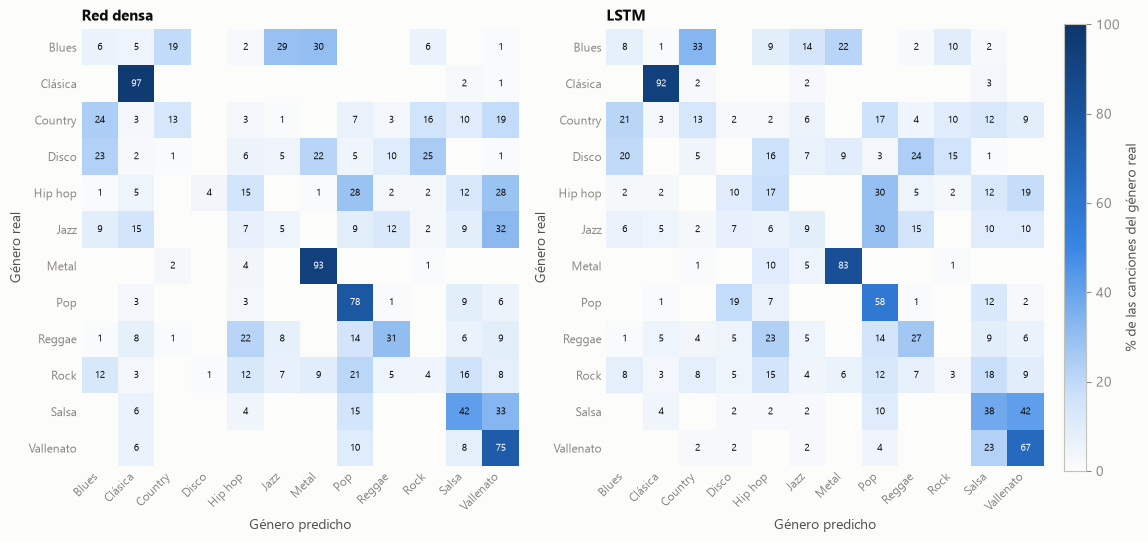

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, m in zip(ejes, res.MODELOS):
    cm, generos = res.confusion_media("B", m)
    im = figuras.confusion(cm, generos, res.MODELOS[m], ax=ax)
fig.colorbar(im, ax=ejes, fraction=0.025, pad=0.02, label="% de las canciones del género real");

## ¿Género o fuente?

Si el modelo reconociera sobre todo la fuente, las canciones de YouTube se predecirían como salsa o
vallenato aunque se equivocara entre ellos, y las de GTZAN como algún género de GTZAN. La tabla
cuenta, por fuente real, cuántas canciones caen en un género de su misma fuente.

In [6]:
f = res.misma_fuente("B")
f["modelo"] = f["modelo"].map(res.MODELOS)
f.set_index(["modelo", "fuente"]).map(lambda v: f"{100 * v:.1f} %")

misma_fuente genero_correcto
modelo    fuente                              
Red densa GTZAN         83.3 %          34.1 %
          YouTube       79.2 %          58.3 %
LSTM      GTZAN         86.6 %          30.9 %
          YouTube       84.4 %          52.1 %

La prueba más directa usa canciones que el modelo B nunca vio: reguetón y rock en español. ¿A qué
género de los 12 las asigna?

In [7]:
for g in ("reggaeton", "rock_es"):
    d = res.fuera_de_escenario(g, "B").rename(index=NOMBRES, columns=res.MODELOS)
    print(f"\n{NOMBRES[g]} (canciones nunca vistas por el modelo B), % por género asignado:")
    print((100 * d).round(0).sort_values("LSTM", ascending=False).head(5).to_string())


Reguetón (canciones nunca vistas por el modelo B), % por género asignado:
           Red densa  LSTM
Vallenato       53.0  48.0
Salsa           15.0  21.0
Pop             16.0  17.0
Hip hop          3.0   6.0
Disco            1.0   3.0

Rock en español (canciones nunca vistas por el modelo B), % por género asignado:
           Red densa  LSTM
Vallenato       33.0  29.0
Salsa           10.0  23.0
Hip hop         11.0  18.0
Pop             16.0  14.0
Clásica          7.0   4.0


In [8]:
for g in ("reggaeton", "rock_es"):
    d = res.fuera_de_escenario(g, "B")
    nuevos = d.loc[["salsa", "vallenato"]].sum()
    print(f"{NOMBRES[g]}: asignadas a salsa o vallenato " + ", ".join(f"{res.MODELOS[m]} {100 * v:.0f} %" for m, v in nuevos.items())
          + f"; a rock: " + ", ".join(f"{res.MODELOS[m]} {100 * v:.0f} %" for m, v in d.loc['rock'].items()))

Reguetón: asignadas a salsa o vallenato Red densa 69 %, LSTM 69 %; a rock: Red densa 0 %, LSTM 0 %
Rock en español: asignadas a salsa o vallenato Red densa 43 %, LSTM 52 %; a rock: Red densa 1 %, LSTM 0 %


Como referencia, el modelo del escenario A (solo GTZAN) ante las cuatro listas de YouTube:

In [9]:
for g in ("salsa", "vallenato", "reggaeton", "rock_es"):
    d = res.fuera_de_escenario(g, "A")
    print(f"{NOMBRES[g]}: " + "; ".join(f"{res.MODELOS[m]} → {NOMBRES[d[m].idxmax()]} {100 * d[m].max():.0f} %"
                                        for m in d.columns))

Salsa: Red densa → Pop 42 %; LSTM → Pop 56 %


Vallenato: Red densa → Pop 44 %; LSTM → Pop 68 %
Reguetón: Red densa → Pop 55 %; LSTM → Pop 71 %
Rock en español: Red densa → Pop 44 %; LSTM → Pop 54 %


El patrón es consistente:

- **Con salsa y vallenato entre las clases**, el 79–84 % de las canciones de YouTube se predice
  como uno de esos dos géneros, aunque el género correcto solo se acierta en el 52–58 %.
- **Con géneros que el modelo B nunca vio**, el reguetón y el rock en español van a parar sobre
  todo a vallenato y salsa: el 69 % del reguetón con ambos modelos y el 43 y 52 % del rock en
  español. A rock va el 1 % o menos, pese a que rock es una de las clases.
- **Sin ningún género de YouTube entre las clases** (modelo A), el destino más frecuente de esas
  canciones es pop, con entre el 42 % y el 71 % según el género y el modelo.

Todo apunta a que los MFCC capturan en buena medida la fuente de la grabación (producción, mezcla,
codificación) y no solo el género. Cuando género y fuente coinciden, como aquí con salsa y vallenato,
una parte de lo que el modelo aprende como «salsa» o «vallenato» es «grabación de YouTube».